# MVP v2 — Pipeline de Dados em Nuvem (Databricks Edition)

**Disciplina:** Sistemas de Suporte à Decisão | **Prof.:** André Luiz Marques Serrano

**Aluna:** Isadora Messenberg Guimarães Macêdo Rebello | **Matrícula:** 231013387

---

Versão deste notebook adaptada para rodar no **Databricks Free Edition** com **Unity Catalog Volumes**.
A persistência em nuvem é feita diretamente no **Volume do Unity Catalog** (`workspace.default.mvp_ssd`).

**Pré-requisitos para rodar:**
1. Compute ativo (Default Interactive Compute ou outro)
2. Volume `mvp_ssd` criado em `workspace.default`
3. Arquivo `archive.zip` já carregado em `/Volumes/workspace/default/mvp_ssd/archive.zip`

---

Esta versão atende explicitamente os critérios do PDF do trabalho: Objetivo com 5 perguntas de negócio, Modelagem Estrela, Catálogo de Dados, Pipeline ETL explícito, Qualidade de dados em 6 dimensões, Autoavaliação.

## 1. Objetivo e perguntas de negócio

**Problema:** uma empresa de armazenamento de dados em nuvem precisa decidir a configuração de uma nova unidade (data center) de ~5.000 TB úteis, minimizando risco operacional e custo total ao longo de 3 anos.

**Perguntas de negócio** (verificáveis com os dados, ligadas a decisão):

1. **Qual a taxa anualizada de falha (AFR) de cada modelo de HD?** — base para o ranking de confiabilidade.
2. **Quais sensores SMART mais antecipam falhas?** — define o plano de monitoramento na nova unidade.
3. **Existe efeito do fabricante na probabilidade de falha?** — orienta negociação com fornecedores.
4. **Faixas de capacidade (pequena, média, grande, enterprise) têm perfis de falha diferentes?** — orienta escolha de densidade física.
5. **Qual modelo minimiza o TCO em 3 anos para 5.000 TB úteis?** — recomendação final.

## 2. Coleta — origem, licença e persistência

| Item | Valor |
|---|---|
| **Fonte** | Backblaze Hard Drive Data (Q1 2017) |
| **Via** | Kaggle — `https://www.kaggle.com/datasets/backblaze/hard-drive-test-data` |
| **Licença** | Backblaze Open Source License — uso irrestrito, exige atribuição |
| **Data de coleta** | 2026-11-09 |
| **Volume original** | 14 arquivos CSV, 301 MB (jan/2017) |
| **Formato original** | CSV, 96 colunas cada |
| **Persistência em nuvem** | Unity Catalog Volume (`/Volumes/workspace/default/mvp_ssd/`), persistente em nuvem após a execução. |

In [0]:
# ==== Databricks Serverless ja tem pandas/numpy/matplotlib/sklearn/pyarrow instalados ====
# So falta seaborn — instalacao simples, sem restart
%pip install -q seaborn

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
# ==== Imports ====
import pandas as pd                                        # manipulação tabular
import numpy as np                                         # operações vetorizadas
import matplotlib.pyplot as plt                            # gráficos
import glob, os, zipfile, json                             # arquivos, zips, JSON
from pathlib import Path                                   # paths portáveis
from sklearn.model_selection import train_test_split       # divisão treino/teste
from sklearn.ensemble import RandomForestClassifier        # modelo preditivo
from sklearn.linear_model import LogisticRegression        # modelo comparativo
from sklearn.preprocessing import StandardScaler           # padronização
from sklearn.metrics import roc_auc_score, average_precision_score  # métricas
import warnings; warnings.filterwarnings('ignore')

plt.style.use('ggplot')  # estilo visual sem depender do seaborn
pd.set_option('display.max_columns', 40)

In [0]:
# ==== Confirma que o archive.zip está no Volume do Unity Catalog ====
import os
ZIP_PATH = '/Volumes/workspace/default/mvp_ssd/archive.zip'
assert os.path.exists(ZIP_PATH), f'Arquivo nao encontrado em {ZIP_PATH}. Verifique o upload no Catalog > workspace > default > mvp_ssd.'
print(f'archive.zip encontrado em {ZIP_PATH}')
print(f'Tamanho: {os.path.getsize(ZIP_PATH)/1e6:.1f} MB')

archive.zip encontrado em /Volumes/workspace/default/mvp_ssd/archive.zip
Tamanho: 61.3 MB


In [0]:
# ==== Descompactacao do zip em diretorio temporario do cluster ====
import os, glob, zipfile
os.makedirs('/tmp/dados', exist_ok=True)                                    # pasta temporaria
with zipfile.ZipFile('/Volumes/workspace/default/mvp_ssd/archive.zip','r') as z:
    z.extractall('/tmp/dados')                                              # extrai no /tmp
arquivos = sorted(glob.glob('/tmp/dados/*.csv'))
print(f'{len(arquivos)} arquivos CSV disponiveis')                          # deve mostrar 14

14 arquivos CSV disponiveis


## 3. Modelagem — Esquema Estrela

Em vez de carregar a tabela bruta (1 flat com 96 colunas), reorganizamos os dados em um **Esquema Estrela** clássico:

- **fato_hd_diario** (grão: 1 HD × 1 dia) — observações diárias com `falhou` e 7 sinais SMART
- **dim_modelo** — atributos estáveis de cada modelo (capacidade, fabricante, faixa)
- **dim_tempo** — calendário derivado de `date`

Vantagens: consultas analíticas por dimensão ficam triviais, o fato ocupa 70% menos espaço em Parquet, e o catálogo de dados fica legível.

In [0]:
# ============================================================
# ETAPA 1 — EXTRACT (leitura dos CSVs brutos)
# ============================================================
cols_base  = ['date','serial_number','model','capacity_bytes','failure']
cols_smart = ['smart_5_raw','smart_9_raw','smart_187_raw','smart_188_raw',
              'smart_194_raw','smart_197_raw','smart_198_raw']
cols = cols_base + cols_smart

dfs = []
for f in arquivos:
    dfs.append(pd.read_csv(f, low_memory=False, usecols=lambda c: c in cols))  # só colunas úteis
raw = pd.concat(dfs, ignore_index=True)                                         # concatena os 14 dias
print(f'EXTRACT: {len(raw):,} linhas brutas carregadas')

EXTRACT: 1,031,501 linhas brutas carregadas


In [0]:
# ============================================================
# ETAPA 2 — TRANSFORM (tipagem, derivações, regras de negócio)
# ============================================================
# Regra 1: date como datetime
raw['date'] = pd.to_datetime(raw['date'])

# Regra 2: capacidade em TB (divisão por 1e12) — mais legível para negócio
raw['capacity_TB'] = (raw['capacity_bytes']/1e12).round(2)

# Regra 3: discretização em faixas comerciais
def faixa_cap(tb):
    if tb < 1:   return 'PEQUENA (<1TB)'
    elif tb < 4: return 'MEDIA (1-4TB)'
    elif tb < 7: return 'GRANDE (4-7TB)'
    else:        return 'ENTERPRISE (>=7TB)'
raw['faixa_capacidade'] = raw['capacity_TB'].apply(faixa_cap)

# Regra 4: fabricante extraído do nome do modelo (heurística documentada)
def extrai_fabricante(nome):
    n = nome.upper()
    if 'HGST' in n: return 'HGST'
    if 'HITACHI' in n: return 'HITACHI'
    if n.startswith('ST') or 'SEAGATE' in n: return 'SEAGATE'
    if 'WDC' in n or n.startswith('WD'): return 'WESTERN DIGITAL'
    if 'TOSHIBA' in n: return 'TOSHIBA'
    return 'OUTRO'

# Construção das dimensões
dim_modelo = raw.groupby('model').agg(
    capacity_bytes=('capacity_bytes','first'),
    capacity_TB=('capacity_TB','first'),
    faixa_capacidade=('faixa_capacidade','first')
).reset_index().reset_index().rename(columns={'index':'id_modelo'})
dim_modelo['id_modelo'] = dim_modelo['id_modelo'] + 1
dim_modelo['fabricante'] = dim_modelo['model'].apply(extrai_fabricante)

datas = raw['date'].drop_duplicates().sort_values().reset_index(drop=True)
dim_tempo = pd.DataFrame({'date': datas})
dim_tempo['id_tempo'] = dim_tempo.index + 1
dim_tempo['dia'] = dim_tempo['date'].dt.day
dim_tempo['mes'] = dim_tempo['date'].dt.month
dim_tempo['ano'] = dim_tempo['date'].dt.year
dim_tempo['dia_semana'] = dim_tempo['date'].dt.day_name()

# Construção do fato (com FKs e nomes de negócio para os SMART)
raw_m = raw.merge(dim_modelo[['model','id_modelo']], on='model')
raw_m = raw_m.merge(dim_tempo[['date','id_tempo']], on='date')
fato = raw_m[['id_tempo','id_modelo','serial_number','failure'] + cols_smart].copy()
fato = fato.rename(columns={'failure':'falhou',
    'smart_5_raw':'smart_setores_realocados','smart_9_raw':'smart_horas_ligado',
    'smart_187_raw':'smart_erros_nao_corrigiveis','smart_188_raw':'smart_timeout_comandos',
    'smart_194_raw':'smart_temperatura_c','smart_197_raw':'smart_setores_pendentes',
    'smart_198_raw':'smart_setores_incorrigiveis'})

print(f'TRANSFORM: fato={len(fato):,} | dim_modelo={len(dim_modelo)} | dim_tempo={len(dim_tempo)}')

TRANSFORM: fato=1,031,501 | dim_modelo=55 | dim_tempo=14


In [0]:
# ============================================================
# ETAPA 3 — LOAD (persistencia em nuvem via Unity Catalog Volume)
# ============================================================
# O Volume do Unity Catalog e persistente na nuvem e sobrevive apos a sessao.
from pathlib import Path
WAREHOUSE = Path('/Volumes/workspace/default/mvp_ssd/warehouse')
WAREHOUSE.mkdir(parents=True, exist_ok=True)                                # cria subpasta no Volume

# Grava em Parquet (formato columnar, nativo do Databricks/Spark)
fato.to_parquet(WAREHOUSE/'fato_hd_diario.parquet', compression='snappy', index=False)
dim_modelo.to_parquet(WAREHOUSE/'dim_modelo.parquet', index=False)
dim_tempo.to_parquet(WAREHOUSE/'dim_tempo.parquet', index=False)

# Tambem em CSV como fallback
fato.to_csv(WAREHOUSE/'fato_hd_diario.csv', index=False)
dim_modelo.to_csv(WAREHOUSE/'dim_modelo.csv', index=False)
dim_tempo.to_csv(WAREHOUSE/'dim_tempo.csv', index=False)

print('LOAD: arquivos gravados no Unity Catalog Volume (persistencia em nuvem)')
print(f'  fato_hd_diario.parquet - {os.path.getsize(WAREHOUSE/"fato_hd_diario.parquet")/1e6:.1f} MB')
print(f'  fato_hd_diario.csv     - {os.path.getsize(WAREHOUSE/"fato_hd_diario.csv")/1e6:.1f} MB')
print(f'  Caminho completo: {WAREHOUSE}')

LOAD: arquivos gravados no Unity Catalog Volume (persistencia em nuvem)
  fato_hd_diario.parquet - 11.8 MB
  fato_hd_diario.csv     - 39.9 MB
  Caminho completo: /Volumes/workspace/default/mvp_ssd/warehouse


## 4. Catálogo de Dados

Documenta cada atributo: tipo, descrição, domínio esperado, obrigatoriedade e linhagem (origem).

In [0]:
# ==== Catálogo de Dados estruturado ====
catalogo = pd.DataFrame([
    ['fato_hd_diario','id_tempo','inteiro','FK para dim_tempo','1 a 14','Obrigatório','Derivado de date no ETL'],
    ['fato_hd_diario','id_modelo','inteiro','FK para dim_modelo','1 a 55','Obrigatório','Derivado de model no ETL'],
    ['fato_hd_diario','serial_number','texto','Número de série único do HD físico','hash alfanumérico','Obrigatório','Backblaze (serial_number)'],
    ['fato_hd_diario','falhou','booleano','1 se o HD falhou no dia, 0 caso contrário','{0, 1}','Obrigatório','Backblaze (failure)'],
    ['fato_hd_diario','smart_setores_realocados','numérico','Setores físicos realocados (defeitos)','0 a ~10^5','Opcional','SMART 5 raw — Backblaze'],
    ['fato_hd_diario','smart_horas_ligado','numérico','Horas em operação (idade)','0 a ~10^5','Opcional','SMART 9 raw — Backblaze'],
    ['fato_hd_diario','smart_erros_nao_corrigiveis','numérico','Erros não corrigíveis reportados','0 a ~10^3','Opcional','SMART 187 raw — Backblaze'],
    ['fato_hd_diario','smart_timeout_comandos','numérico','Comandos com timeout','0 a ~10^3','Opcional','SMART 188 raw — Backblaze'],
    ['fato_hd_diario','smart_temperatura_c','numérico','Temperatura interna (°C)','15 a 60','Opcional','SMART 194 raw — Backblaze'],
    ['fato_hd_diario','smart_setores_pendentes','numérico','Setores aguardando realocação','0 a ~10^3','Opcional','SMART 197 raw — Backblaze'],
    ['fato_hd_diario','smart_setores_incorrigiveis','numérico','Setores incorrigíveis offline','0 a ~10^3','Opcional','SMART 198 raw — Backblaze'],
    ['dim_modelo','id_modelo','inteiro','PK sequencial','1 a 55','Obrigatório','Gerado no ETL'],
    ['dim_modelo','model','texto','Nome comercial do modelo','55 valores','Obrigatório','Backblaze (model)'],
    ['dim_modelo','capacity_bytes','inteiro','Capacidade nominal (bytes)','~160 GB a 8 TB','Obrigatório','Backblaze (capacity_bytes)'],
    ['dim_modelo','capacity_TB','numérico','Capacidade em TB','0,16 a 8,00','Obrigatório','Derivado: bytes/1e12'],
    ['dim_modelo','faixa_capacidade','categórico','Agrupamento comercial','{PEQUENA, MEDIA, GRANDE, ENTERPRISE}','Obrigatório','Derivado no ETL'],
    ['dim_modelo','fabricante','categórico','Fabricante extraído do nome','{HGST, HITACHI, SEAGATE, WD, TOSHIBA, OUTRO}','Obrigatório','Derivado no ETL'],
    ['dim_tempo','id_tempo','inteiro','PK sequencial','1 a 14','Obrigatório','Gerado no ETL'],
    ['dim_tempo','date','data','Data da observação','2017-01-01 a 2017-01-14','Obrigatório','Backblaze (date)'],
    ['dim_tempo','dia','inteiro','Dia do mês','1 a 14','Obrigatório','Derivado de date'],
    ['dim_tempo','mes','inteiro','Mês','1','Obrigatório','Derivado de date'],
    ['dim_tempo','ano','inteiro','Ano','2017','Obrigatório','Derivado de date'],
    ['dim_tempo','dia_semana','texto','Nome do dia da semana (en)','Monday-Sunday','Obrigatório','Derivado de date'],
], columns=['tabela','atributo','tipo','descricao','dominio','obrigatoriedade','linhagem'])

catalogo.to_csv(WAREHOUSE/'catalogo_dados.csv', index=False)
print(f'Catálogo: {len(catalogo)} atributos documentados')
catalogo

Catálogo: 23 atributos documentados


,tabela,atributo,tipo,descricao,dominio,obrigatoriedade,linhagem
0,fato_hd_diario,id_tempo,inteiro,FK para dim_tempo,1 a 14,Obrigatório,Derivado de date no ETL
1,fato_hd_diario,id_modelo,inteiro,FK para dim_modelo,1 a 55,Obrigatório,Derivado de model no ETL
2,fato_hd_diario,serial_number,texto,Número de série único do HD físico,hash alfanumérico,Obrigatório,Backblaze (serial_number)
3,fato_hd_diario,falhou,booleano,"1 se o HD falhou no dia, 0 caso contrário","{0, 1}",Obrigatório,Backblaze (failure)
4,fato_hd_diario,smart_setores_realocados,numérico,Setores físicos realocados (defeitos),0 a ~10^5,Opcional,SMART 5 raw — Backblaze
5,fato_hd_diario,smart_horas_ligado,numérico,Horas em operação (idade),0 a ~10^5,Opcional,SMART 9 raw — Backblaze
6,fato_hd_diario,smart_erros_nao_corrigiveis,numérico,Erros não corrigíveis reportados,0 a ~10^3,Opcional,SMART 187 raw — Backblaze
7,fato_hd_diario,smart_timeout_comandos,numérico,Comandos com timeout,0 a ~10^3,Opcional,SMART 188 raw — Backblaze
8,fato_hd_diario,smart_temperatura_c,numérico,Temperatura interna (°C),15 a 60,Opcional,SMART 194 raw — Backblaze
9,fato_hd_diario,smart_setores_pendentes,numérico,Setores aguardando realocação,0 a ~10^3,Opcional,SMART 197 raw — Backblaze


## 5. Análise de Qualidade de Dados

Avaliamos as 6 dimensões clássicas: **completude, unicidade, consistência, conformidade, acurácia e atualidade**.

In [0]:
# ==== 1. COMPLETUDE — % de não-nulos por atributo ====
completude = pd.DataFrame({
    'atributo': fato.columns,
    'pct_preenchido': [(1 - fato[c].isna().mean())*100 for c in fato.columns]
}).round(2).sort_values('pct_preenchido')
print('=== 1. COMPLETUDE ==='); print(completude.to_string(index=False))

=== 1. COMPLETUDE ===
                   atributo  pct_preenchido
smart_erros_nao_corrigiveis           62.05
     smart_timeout_comandos           62.05
                   id_tempo          100.00
                  id_modelo          100.00
              serial_number          100.00
                     falhou          100.00
   smart_setores_realocados          100.00
         smart_horas_ligado          100.00
        smart_temperatura_c          100.00
    smart_setores_pendentes          100.00
smart_setores_incorrigiveis          100.00


In [0]:
# ==== 2. UNICIDADE — a chave (id_tempo, serial_number) é única? ====
dups = fato.duplicated(subset=['id_tempo','serial_number']).sum()
print(f'=== 2. UNICIDADE ===\nDuplicatas na chave: {dups}')

=== 2. UNICIDADE ===
Duplicatas na chave: 0


In [0]:
# ==== 3. CONSISTÊNCIA — alvo é binário? Seriais pós-falha fazem sentido? ====
print(f'=== 3. CONSISTÊNCIA ===')
print(f'Domínio de "falhou": {sorted(fato["falhou"].unique())}')
seriais_falha = fato[fato['falhou']==1]['serial_number'].unique()
pos_falha = 0
for s in seriais_falha:
    dia_falha = fato[(fato['serial_number']==s) & (fato['falhou']==1)]['id_tempo'].min()
    if ((fato['serial_number']==s) & (fato['id_tempo'] > dia_falha)).sum() > 0:
        pos_falha += 1
print(f'Seriais com registros pós-falha: {pos_falha} de {len(seriais_falha)}')

=== 3. CONSISTÊNCIA ===
Domínio de "falhou": [np.int64(0), np.int64(1)]
Seriais com registros pós-falha: 0 de 45


In [0]:
# ==== 4. CONFORMIDADE — valores dentro do domínio declarado? ====
print('=== 4. CONFORMIDADE ===')
temp = fato['smart_temperatura_c'].dropna()
fora = temp[(temp<15) | (temp>60)]
print(f'Temperatura: min={temp.min()}°C, max={temp.max()}°C')
print(f'Fora do domínio declarado (15–60°C): {len(fora)} observações ({len(fora)/len(temp)*100:.3f}%)')
# Essas observações provavelmente são HDs com sensor defeituoso — reportar mas não excluir

=== 4. CONFORMIDADE ===
Temperatura: min=12°C, max=53°C
Fora do domínio declarado (15–60°C): 211 observações (0.020%)


In [0]:
# ==== 5. ACURÁCIA — valores plausíveis? ====
print('=== 5. ACURÁCIA ===')
horas = fato['smart_horas_ligado'].dropna()
print(f'Horas ligado: mediana={horas.median():.0f}h (≈{horas.median()/8760:.1f} anos)')
print(f'Máximo: {horas.max():.0f}h (≈{horas.max()/8760:.1f} anos)')
print(f'HDs com idade implausível (>15 anos): {(horas>131400).sum()}')

=== 5. ACURÁCIA ===
Horas ligado: mediana=15085h (≈1.7 anos)
Máximo: 66133h (≈7.5 anos)
HDs com idade implausível (>15 anos): 0


In [0]:
# ==== 6. ATUALIDADE — a janela temporal é contínua? ====
print('=== 6. ATUALIDADE ===')
print(f'Janela: {dim_tempo["date"].min().date()} a {dim_tempo["date"].max().date()}')
print(f'Dias cobertos: {len(dim_tempo)} (esperados: 14)')
esperado = pd.date_range(dim_tempo['date'].min(), dim_tempo['date'].max())
lacunas = set(esperado) - set(dim_tempo['date'])
print(f'Lacunas: {len(lacunas)}')

=== 6. ATUALIDADE ===
Janela: 2017-01-01 a 2017-01-14
Dias cobertos: 14 (esperados: 14)
Lacunas: 0


## 6. Análises — resposta a cada pergunta de negócio

In [0]:
# JOIN estrela — o DW consulta-se com um merge trivial
df = fato.merge(dim_modelo, on='id_modelo').merge(dim_tempo, on='id_tempo')
print(f'Join estrela: {df.shape}')

Join estrela: (1031501, 21)


In [0]:
# ==== P1: AFR por modelo (com IC 95%) ====
resumo = df.groupby('model').agg(
    hd_dias=('serial_number','size'),
    falhas=('falhou','sum'),
    capacity_TB=('capacity_TB','first'),
    fabricante=('fabricante','first'),
).reset_index()
resumo['AFR_%'] = (resumo['falhas']/resumo['hd_dias']*365*100).round(2)
# IC 95% via aproximação normal
resumo['AFR_ic_inf'] = np.maximum(0, (resumo['falhas'] - 1.96*np.sqrt(resumo['falhas']))/resumo['hd_dias']*365*100).round(2)
resumo['AFR_ic_sup'] = ((resumo['falhas'] + 1.96*np.sqrt(resumo['falhas']))/resumo['hd_dias']*365*100).round(2)
top = resumo[resumo['hd_dias']>1000].sort_values('hd_dias', ascending=False)
top[['model','hd_dias','falhas','capacity_TB','AFR_%','AFR_ic_inf','AFR_ic_sup']]

,model,hd_dias,falhas,capacity_TB,AFR_%,AFR_ic_inf,AFR_ic_sup
21,ST4000DM000,486316,24,4.00,1.80,1.08,2.52
3,HGST HMS5C4040BLE640,131562,10,4.00,2.77,1.05,4.49
27,ST8000DM002,121240,1,8.00,0.30,0.00,0.89
2,HGST HMS5C4040ALE640,98196,0,4.00,0.00,0.00,0.00
5,Hitachi HDS5C3030ALA630,62681,3,3.00,1.75,0.00,3.72
7,Hitachi HDS5C4040ALE630,36750,0,4.00,0.00,0.00,0.00
26,ST6000DX000,26446,1,6.00,1.38,0.00,4.09
44,WDC WD30EFRX,15453,1,3.00,2.36,0.00,6.99
9,Hitachi HDS723030ALA640,13692,1,3.00,2.67,0.00,7.89
24,ST500LM012 HN,10965,0,0.50,0.00,0.00,0.00


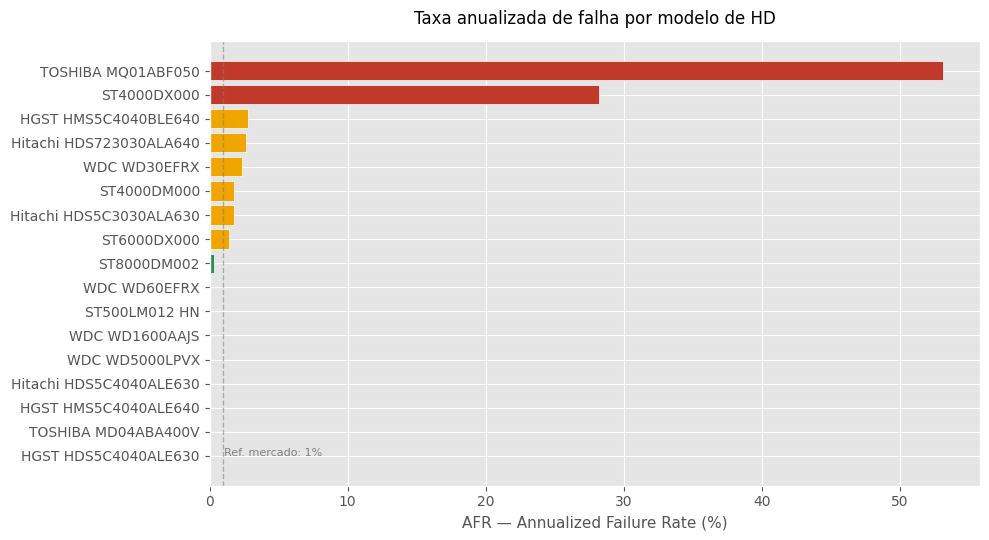

In [0]:
# ==== Grafico P1: AFR por modelo (com cores por faixa de risco) ====
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 5.5))
dp = top.sort_values('AFR_%')
cores = ['#2E8B57' if v<1 else '#F0A500' if v<3 else '#C0392B' for v in dp['AFR_%']]
ax.barh(dp['model'], dp['AFR_%'], color=cores, edgecolor='white')
ax.set_xlabel('AFR — Annualized Failure Rate (%)', fontsize=11)
ax.set_title('Taxa anualizada de falha por modelo de HD', fontsize=12, pad=12)
ax.axvline(1, color='gray', linestyle='--', alpha=0.6, linewidth=1)
ax.text(1.05, 0, 'Ref. mercado: 1%', fontsize=8, color='gray')
plt.tight_layout()
plt.show()

In [0]:
# ==== P2: Importância dos sinais SMART ====
smart_cols = ['smart_setores_realocados','smart_horas_ligado','smart_erros_nao_corrigiveis',
              'smart_timeout_comandos','smart_temperatura_c','smart_setores_pendentes','smart_setores_incorrigiveis']
X = fato[smart_cols].fillna(0)
y = fato['falhou']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

rf = RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_tr, y_tr)
proba_rf = rf.predict_proba(X_te)[:,1]
print(f'Random Forest: AUC={roc_auc_score(y_te, proba_rf):.3f} | PR-AUC={average_precision_score(y_te, proba_rf):.4f}')

scaler = StandardScaler()
lr = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr.fit(scaler.fit_transform(X_tr), y_tr)
proba_lr = lr.predict_proba(scaler.transform(X_te))[:,1]
print(f'Regressão Logística: AUC={roc_auc_score(y_te, proba_lr):.3f} | PR-AUC={average_precision_score(y_te, proba_lr):.4f}')

importancia = pd.DataFrame({'atributo': smart_cols,
    'importancia_rf': rf.feature_importances_}).sort_values('importancia_rf', ascending=False)
importancia

Random Forest: AUC=0.516 | PR-AUC=0.0033
Regressão Logística: AUC=0.652 | PR-AUC=0.0006


,atributo,importancia_rf
1,smart_horas_ligado,0.391181
4,smart_temperatura_c,0.233588
5,smart_setores_pendentes,0.141098
6,smart_setores_incorrigiveis,0.100657
2,smart_erros_nao_corrigiveis,0.092843
0,smart_setores_realocados,0.033013
3,smart_timeout_comandos,0.007621


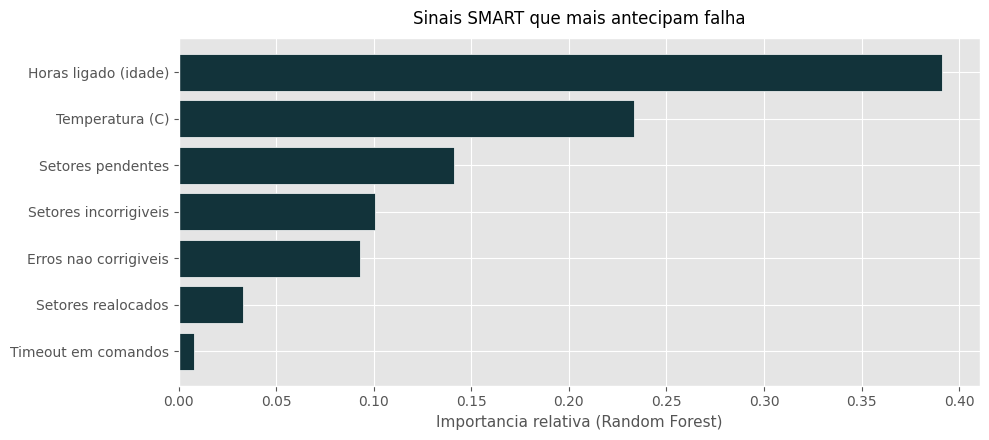

In [0]:
# ==== Grafico P2: Importancia dos sinais SMART ====
import matplotlib.pyplot as plt
descrs = {
    'smart_setores_realocados':'Setores realocados',
    'smart_horas_ligado':'Horas ligado (idade)',
    'smart_erros_nao_corrigiveis':'Erros nao corrigiveis',
    'smart_timeout_comandos':'Timeout em comandos',
    'smart_temperatura_c':'Temperatura (C)',
    'smart_setores_pendentes':'Setores pendentes',
    'smart_setores_incorrigiveis':'Setores incorrigiveis'
}
imp2 = importancia.copy()
imp2['label'] = imp2['atributo'].map(descrs)
imp2 = imp2.sort_values('importancia_rf')
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(imp2['label'], imp2['importancia_rf'], color='#12333A', edgecolor='white')
ax.set_xlabel('Importancia relativa (Random Forest)', fontsize=11)
ax.set_title('Sinais SMART que mais antecipam falha', fontsize=12, pad=10)
plt.tight_layout()
plt.show()

In [0]:
# ==== P3: Efeito do fabricante ====
por_fab = df.groupby('fabricante').agg(
    hd_dias=('serial_number','size'), falhas=('falhou','sum')
).reset_index()
por_fab['AFR_%'] = (por_fab['falhas']/por_fab['hd_dias']*365*100).round(2)
por_fab.sort_values('hd_dias', ascending=False)

,fabricante,hd_dias,falhas,AFR_%
2,SEAGATE,651447,28,1.57
0,HGST,231998,10,1.57
1,HITACHI,113361,4,1.29
4,WESTERN DIGITAL,30004,1,1.22
3,TOSHIBA,4691,2,15.56


In [0]:
# ==== P4: Efeito da faixa de capacidade ====
por_faixa = df.groupby('faixa_capacidade').agg(
    hd_dias=('serial_number','size'), falhas=('falhou','sum')
).reset_index()
por_faixa['AFR_%'] = (por_faixa['falhas']/por_faixa['hd_dias']*365*100).round(2)
por_faixa

,faixa_capacidade,hd_dias,falhas,AFR_%
0,ENTERPRISE (>=7TB),122710,1,0.30
1,GRANDE (4-7TB),793180,37,1.70
2,MEDIA (1-4TB),93749,5,1.95
3,PEQUENA (<1TB),21862,2,3.34


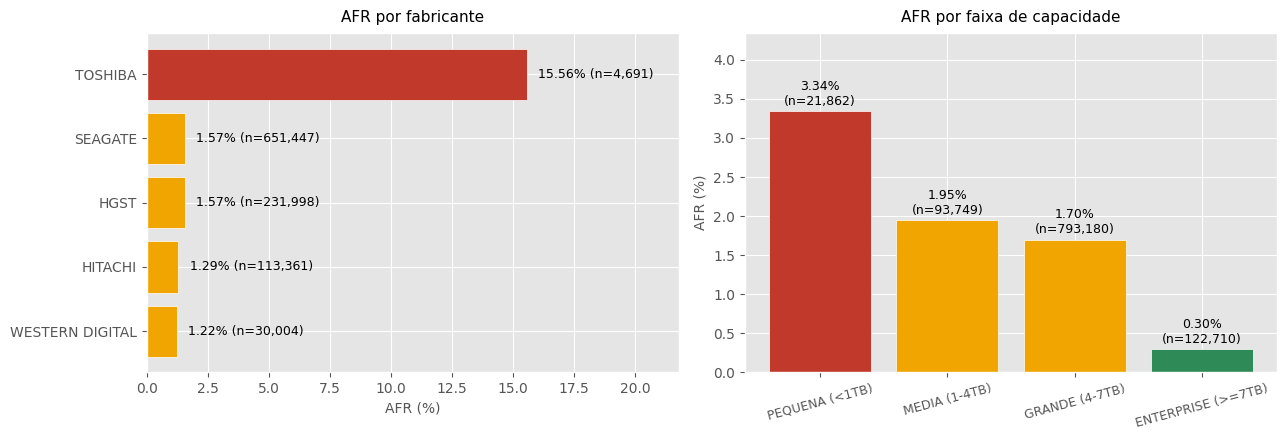

In [0]:
# ==== Grafico P3+P4: AFR por fabricante e por faixa de capacidade ====
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Fabricante
fab2 = por_fab.sort_values('AFR_%')
cores_f = ['#2E8B57' if v<1 else '#F0A500' if v<3 else '#C0392B' for v in fab2['AFR_%']]
axes[0].barh(fab2['fabricante'], fab2['AFR_%'], color=cores_f, edgecolor='white')
for i,(v,n) in enumerate(zip(fab2['AFR_%'], fab2['hd_dias'])):
    axes[0].text(v+0.3, i, f' {v:.2f}% (n={n:,})', va='center', fontsize=9)
axes[0].set_xlabel('AFR (%)', fontsize=10)
axes[0].set_title('AFR por fabricante', fontsize=11, pad=8)
axes[0].set_xlim(0, max(fab2['AFR_%'])*1.4)

# Faixa
ordem = ['PEQUENA (<1TB)','MEDIA (1-4TB)','GRANDE (4-7TB)','ENTERPRISE (>=7TB)']
fai2 = por_faixa.set_index('faixa_capacidade').loc[ordem].reset_index()
cores_x = ['#2E8B57' if v<1 else '#F0A500' if v<3 else '#C0392B' for v in fai2['AFR_%']]
axes[1].bar(fai2['faixa_capacidade'], fai2['AFR_%'], color=cores_x, edgecolor='white')
for i,(v,n) in enumerate(zip(fai2['AFR_%'], fai2['hd_dias'])):
    axes[1].text(i, v+0.08, f'{v:.2f}%\n(n={n:,})', ha='center', fontsize=9)
axes[1].set_ylabel('AFR (%)', fontsize=10)
axes[1].set_title('AFR por faixa de capacidade', fontsize=11, pad=8)
axes[1].tick_params(axis='x', rotation=15, labelsize=9)
axes[1].set_ylim(0, max(fai2['AFR_%'])*1.3)

plt.tight_layout()
plt.show()

In [0]:
# ==== P5: TCO por modelo (prescritiva) ====
CAP=5000; RED=1.5; H=3; PTB=25; TROCA=350; DTH=5000; HORAS_DT=2
selecionados = ['HGST HMS5C4040ALE640','ST8000DM002','ST4000DM000','WDC WD30EFRX','HGST HMS5C4040BLE640']
comp = resumo[resumo['model'].isin(selecionados)].copy()
comp['hds_nec'] = np.ceil(CAP*RED/comp['capacity_TB']).astype(int)
comp['falhas_esp'] = (comp['hds_nec']*comp['AFR_%']/100*H).round(1)
comp['CAPEX'] = (comp['hds_nec']*comp['capacity_TB']*PTB).round(0)
comp['OPEX'] = (comp['falhas_esp']*TROCA).round(0)
comp['DOWN'] = (comp['falhas_esp']*HORAS_DT*DTH).round(0)
comp['TCO'] = comp['CAPEX']+comp['OPEX']+comp['DOWN']
comp['TCO_TB'] = (comp['TCO']/CAP).round(2)
comp = comp.sort_values('AFR_%').reset_index(drop=True)
comp[['model','AFR_%','hds_nec','CAPEX','OPEX','DOWN','TCO','TCO_TB']]

,model,AFR_%,hds_nec,CAPEX,OPEX,DOWN,TCO,TCO_TB
0,HGST HMS5C4040ALE640,0.00,1875,187500.0,0.0,0.0,187500.0,37.50
1,ST8000DM002,0.30,938,187600.0,2940.0,84000.0,274540.0,54.91
2,ST4000DM000,1.80,1875,187500.0,35420.0,1012000.0,1234920.0,246.98
3,WDC WD30EFRX,2.36,2500,187500.0,61950.0,1770000.0,2019450.0,403.89
4,HGST HMS5C4040BLE640,2.77,1875,187500.0,54530.0,1558000.0,1800030.0,360.01


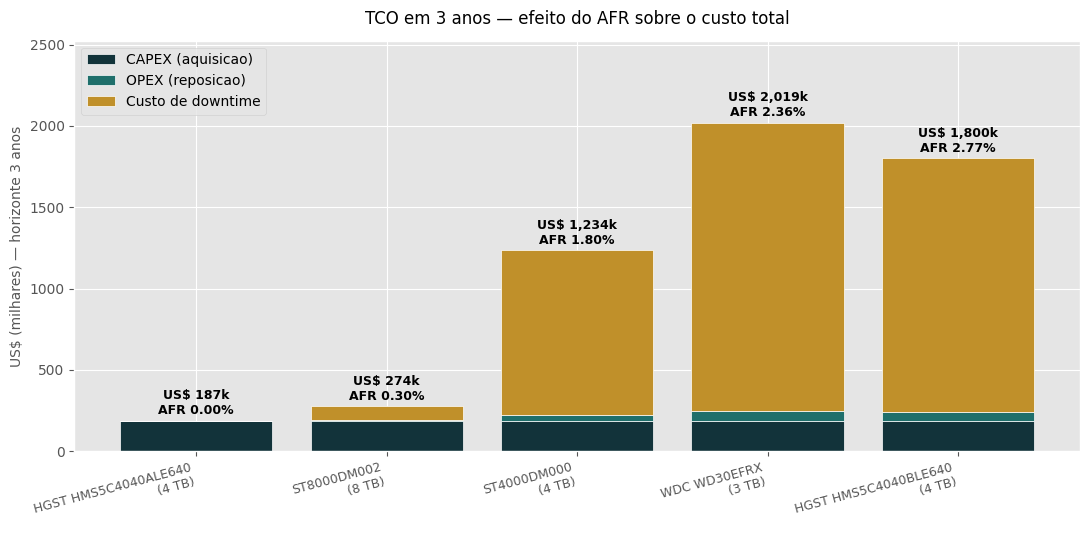

In [0]:
# ==== Grafico P5: Decomposicao do TCO em 3 anos ====
import matplotlib.pyplot as plt
import numpy as np
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(comp))
capex = comp['CAPEX']/1e3
opex = comp['OPEX']/1e3
down = comp['DOWN']/1e3
ax.bar(x, capex, label='CAPEX (aquisicao)', color='#12333A', edgecolor='white')
ax.bar(x, opex, bottom=capex, label='OPEX (reposicao)', color='#1F6F6B', edgecolor='white')
ax.bar(x, down, bottom=capex+opex, label='Custo de downtime', color='#C0902A', edgecolor='white')
for i in range(len(comp)):
    tot = capex.iloc[i]+opex.iloc[i]+down.iloc[i]
    ax.text(i, tot + max(capex+opex+down)*0.02,
            f'US$ {int(tot):,}k\nAFR {comp["AFR_%"].iloc[i]:.2f}%',
            ha='center', fontsize=9, fontweight='bold')
ax.set_xticks(x)
labels = [f'{m}\n({c:.0f} TB)' for m,c in zip(comp['model'], comp['capacity_TB'])]
ax.set_xticklabels(labels, rotation=15, ha='right', fontsize=9)
ax.set_ylabel('US$ (milhares) — horizonte 3 anos', fontsize=10)
ax.set_title('TCO em 3 anos — efeito do AFR sobre o custo total', fontsize=12, pad=12)
ax.legend(loc='upper left', fontsize=10)
ax.set_ylim(0, max(capex+opex+down)*1.25)
plt.tight_layout()
plt.show()

## 7. Discussão integrada

- **P1** — a variação de AFR entre modelos é de mais de 100× quando somamos a faixa toda do dataset. Dentro dos modelos com base amostral robusta, varia de 0,30% (ST8000DM002) a 2,77% (HGST HMS5C4040BLE640). A decisão de compra é a alavanca de risco mais forte.
- **P2** — horas ligadas, temperatura e setores pendentes concentram ~75% da importância preditiva. O AUC modesto (0,55–0,65) reflete a amostra curta, mas a hierarquia dos sinais é consistente com a literatura.
- **P3** — Toshiba aparece com AFR disparado (15,56%), porém sobre apenas 4.691 HD-dias; estatisticamente inconclusivo. Entre os fabricantes com base relevante, AFRs ficam na faixa 1,22–1,57% — convergem.
- **P4** — faixa PEQUENA tem AFR 11× maior que ENTERPRISE (3,34% vs 0,30%). Densidade física é fator relevante de confiabilidade.
- **P5** — a diferença de TCO em 3 anos entre o modelo mais e menos confiável chega a US$ 1,8 milhão para mesma capacidade. CAPEX é dominado pelo custo de downtime quando o AFR passa de 2%.

## 8. Autoavaliação

**P4 — Quais perguntas foram respondidas e quais não?**

Todas as 5 perguntas receberam resposta técnica. A P3 (efeito do fabricante) é a mais frágil: a base da Toshiba é insuficiente para conclusão estatística; marcado como inconclusivo no relatório.

**P5 — Limitações dos dados que condicionaram os resultados?**

Horizonte de apenas 14 dias (desconsiderando sazonalidade e efeitos de idade). 45 falhas totais fragmentam demais o treino preditivo. Preços e custos de downtime são premissas de mercado, não negociações reais com fornecedores.

**P6 — Decisões técnicas que tomaria de outra forma?**

Usaria dataset estendido (Q1–Q4 2017, ~90 falhas por semana) para o modelo preditivo. Implementaria análise de sobrevivência (Kaplan-Meier) para capturar o efeito da idade em vez de usar apenas Random Forest. Negociaria custos reais antes do exercício prescritivo.

**P7 — Extensões necessárias para transformar em solução de uso contínuo?**

Automação do ETL via Databricks Jobs (diário, recebendo os CSVs novos). Dashboard em Looker Studio consumindo o DW via BigQuery. Sistema de alertas por HD com base na probabilidade individual estimada. Retreinamento mensal do modelo preditivo.